In [115]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize_scalar

In [116]:
df = pd.read_csv('Merged_pop_reserv_all_more_5.csv',index_col=0)
New_york = df.loc[df['POPESTIMATE2019']> 10000000].index.values
df = df.drop(New_york)

In [117]:
df.columns

Index(['city', 'STNAME', 'POPESTIMATE2019', '#_of_reservations',
       'Per_capita_rate', 'POPEST2019LOG'],
      dtype='object')

In [140]:
# take values x and y values from the 
x_list = []
for pop in df['POPESTIMATE2019']:
    x_list.append(int(pop))
x = np.array(x_list)
y_list = []
for reservation in df['#_of_reservations']:
    y_list.append(int(reservation))
y = np.array(y_list)

In [141]:
y

array([13, 13, 37, ...,  8, 34,  8])

In [142]:
#defining a cost function: a measure of the ‘goodness’ of the linear relation that we want to maximize.A good indicator is the Pearson product-moment correlation coefficient r, which identifies the strength of the linear correlation between two variables.
def cost_function(e):
    #y and x are already defined
    r = np.corrcoef(y,x**e) #returns correlation matrix
    #print each iteration
    print('r value: {:0.4f} exp: {:.4f}'.format(r[0][1],e)) 
    return -abs(r[0][1])

In [143]:
minimize_scalar(cost_function)

r value: nan exp: 0.0000
r value: 0.6146 exp: 1.0000
r value: 0.3784 exp: 2.6180
r value: 0.6146 exp: 1.0000
r value: 0.5045 exp: 1.6180
r value: 0.5950 exp: 0.6180
r value: 0.6208 exp: 0.9206
r value: 0.6225 exp: 0.8684
r value: 0.6225 exp: 0.8504
r value: 0.6226 exp: 0.8558
r value: 0.6226 exp: 0.8560
r value: 0.6226 exp: 0.8560
r value: 0.6226 exp: 0.8560
r value: 0.6226 exp: 0.8560
r value: 0.6226 exp: 0.8560


C:\Users\alexp\anaconda3\lib\site-packages\numpy\lib\function_base.py:2559: RuntimeWarning: invalid value encountered in true_divide
  c /= stddev[:, None]
C:\Users\alexp\anaconda3\lib\site-packages\numpy\lib\function_base.py:2560: RuntimeWarning: invalid value encountered in true_divide
  c /= stddev[None, :]


     fun: -0.6225552359802357
    nfev: 15
     nit: 11
 success: True
       x: 0.8559881834333982

In [145]:
exp_x = []
for lin in x_list:
    lin_x = lin**0.8560
    exp_x.append(lin_x)

In [146]:
df['Trans_pop'] = exp_x
exp_x_nump = np.array(exp_x).reshape((-1, 1))

<AxesSubplot:xlabel='Trans_pop', ylabel='#_of_reservations'>

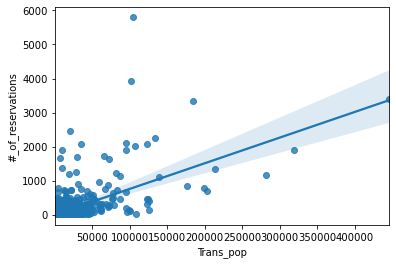

In [148]:
import seaborn as sns
sns.regplot(x='Trans_pop',y='#_of_reservations',data=df)

In [149]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
model = LinearRegression()
model.fit(exp_x_nump, y)
r_sq = model.score(exp_x_nump, y)
print('coefficient of determination:', r_sq)


coefficient of determination: 0.38757502177126346


In [150]:
print('slope:', model.coef_)
print('intercept:', model.intercept_)

slope: [0.00754551]
intercept: -0.6391142733399349


In [151]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
transformer = PolynomialFeatures(degree=2, include_bias=False)
transformer.fit(exp_x_nump)
x_ = transformer.transform(exp_x_nump)
model = LinearRegression().fit(x_, y)
r_sq = model.score(x_, y)
print('coefficient of determination:', r_sq)

print('intercept:', model.intercept_)

print('coefficients:', model.coef_)


coefficient of determination: 0.3886444726734144
intercept: -4.2547877644799925
coefficients: [ 8.10060857e-03 -2.68380736e-09]


In [152]:
df.loc[(df["Trans_pop"] < 120000) & (df["#_of_reservations"] > 2000)]

,city,STNAME,POPESTIMATE2019,#_of_reservations,Per_capita_rate,POPEST2019LOG,Trans_pop
427,Boulder,Colorado,105673.0,2465,0.023327,11.568105,19976.215555
1051,Denver,Colorado,727211.0,5798,0.007973,13.496972,104131.311023
3446,Portland,Oregon,654741.0,2106,0.003217,13.391995,95182.152949
3758,Salt Lake City,Utah,200567.0,2076,0.010351,12.208904,34572.764957
3871,Seattle,Washington,753675.0,2010,0.002667,13.532717,107366.698245
4433,Washington,District of Columbia,705749.0,3928,0.005566,13.467015,101494.996368


In [89]:
df.loc[(df["Trans_pop"] < 120000) & (df["#_of_reservations"] > 1000)]

,city,STNAME,POPESTIMATE2019,#_of_reservations,Trans_pop
52,Alexandria,Virginia,159428.0,1240,28405.032850
219,Baltimore,Maryland,593490.0,1127,87506.814648
427,Boulder,Colorado,105673.0,2465,19976.215555
443,Bozeman,Montana,49831.0,1366,10496.866161
854,Colorado Springs,Colorado,478221.0,1629,72738.127806
1051,Denver,Colorado,727211.0,5798,104131.311023
1417,Fort Collins,Colorado,170243.0,1690,30046.596843
1805,Helena,Montana,33124.0,1666,7400.178853
2272,Las Vegas,Nevada,651319.0,1897,94756.158951
2379,Littleton,Colorado,48065.0,1884,10177.604689


In [90]:
df.loc[(df["Trans_pop"] > 100000) & (df["#_of_reservations"] < 2000)]

,city,STNAME,POPESTIMATE2019,#_of_reservations,Trans_pop
711,Charlotte,North Carolina,885708.0,313,123276.622072
744,Chicago,Illinois,2693976.0,1911,319460.396502
868,Columbus,Ohio,898553.0,471,124805.408447
981,Dallas,Texas,1343573.0,833,176113.093315
1438,Fort Worth,Texas,909585.0,394,126115.903647
1811,Hempstead,New York,766980.0,7,108987.110264
1920,Houston,Texas,2320268.0,1163,281125.769256
1984,Indianapolis,Indiana,886220.0,461,123337.620102
2021,Jacksonville,Florida,911507.0,138,126343.983901
3335,Philadelphia,Pennsylvania,1584064.0,700,202770.817400
